In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)

# Experiment 1: Positional Encoding

In [50]:
sentence1 = ["I", "love", "NLP"]
sentence2 = ["NLP", "love", "I"]

embeddings = {
    "I":    [1.0, 0.5, 0.2, 0.1],
    "love": [0.2, 1.0, 0.4, 0.3],
    "NLP":  [0.1, 0.3, 1.0, 0.8]
}

def embed(sentence):
  return np.array([embeddings[token] for token in sentence])

X1 = embed(sentence1)
X2 = embed(sentence2)

def positional_encoding(seq_len, d_model):
  PE = np.zeros((seq_len, d_model))

  for pos in range(seq_len):
    for i in range(0, d_model, 2):
      angle = pos / (10000 ** (i/d_model))
      PE[pos, i] = np.sin(angle)
      PE[pos, i + 1] = np.cos(angle)

  return PE


def softmax(x, axis=-1):
  x = x - np.max(x, axis=axis, keepdims=True)
  return np.exp(x) / np.sum(np.exp(x), axis=axis, keepdims=True)


def attention(Z):
  d_k = Z.shape[-1]
  scores = (Z @ Z.T)/np.sqrt(d_k)
  weights = softmax(scores)
  output = weights @ Z
  return output, weights

sen1_no_pos_encode, a1_no_pos_encode = attention(X1)
sen2_no_pos_encode, a2_no_pos_encode = attention(X2)

print("Original output:\n", sen1_no_pos_encode)
print("Reversed output:\n", sen2_no_pos_encode)

# Reverse output rows to align identical tokens
diff_no = np.max(np.abs(sen1_no_pos_encode - sen2_no_pos_encode[::-1]))
print("Difference after alignment:", diff_no)

PE = positional_encoding(3, 4)

Z1 = X1 + PE
Z2 = X2 + PE

sen1_pos_encode, a1_pos_encode = attention(Z1)
sen2_pos_encode, a2_pos_encode = attention(Z2)

print("Original output:\n", sen1_pos_encode)
print("Reversed output:\n", sen2_pos_encode)

diff_pe = np.max(np.abs(sen1_pos_encode - sen2_pos_encode[::-1]))
print("Difference after alignment:", diff_pe)




Original output:
 [[0.497 0.604 0.485 0.357]
 [0.407 0.625 0.533 0.401]
 [0.352 0.562 0.621 0.476]]
Reversed output:
 [[0.352 0.562 0.621 0.476]
 [0.407 0.625 0.533 0.401]
 [0.497 0.604 0.485 0.357]]
Difference after alignment: 1.1102230246251565e-16
Original output:
 [[1.02  1.23  0.44  1.314]
 [1.02  1.206 0.453 1.325]
 [1.016 0.586 0.721 1.549]]
Reversed output:
 [[0.595 1.256 0.726 1.564]
 [0.874 1.172 0.584 1.44 ]
 [1.362 0.705 0.403 1.272]]
Difference after alignment: 0.6697945672706516


# 12. Permutation experiment

In [51]:
S1 = ["dog", "bites", "man"]
S2 = ["man", "bites", "dog"]

d_model = 4
rng = np.random.default_rng(42)
vocab = ["dog", "bites", "man"]

embeddings = {
    token: rng.normal(size=d_model)
    for token in vocab
}

def get_embeddings(sentence):
    return np.array([embeddings[token] for token in sentence])

X1 = get_embeddings(S1)
X2 = get_embeddings(S2)

PE = positional_encoding(len(S1), d_model)

Y1_no, A1_no = attention(X1)
Y2_no, A2_no = attention(X2)

print("WITHOUT POSITIONAL ENCODING")

print("\nS1 Output:\n", Y1_no)
print("\nS2 Output:\n", Y2_no)

print("\nS1 Attention Weights:\n", A1_no)
print("\nS2 Attention Weights:\n", A2_no)

Z1 = X1 + PE
Z2 = X2 + PE

Y1_pe, A1_pe = attention(Z1)
Y2_pe, A2_pe = attention(Z2)

print("WITH POSITIONAL ENCODING")

print("\nS1 Transformer Input:\n", Z1)
print("\nS2 Transformer Input:\n", Z2)

print("\nS1 Output:\n", Y1_pe)
print("\nS2 Output:\n", Y2_pe)

print("\nS1 Attention Weights:\n", A1_pe)
print("\nS2 Attention Weights:\n", A2_pe)





WITHOUT POSITIONAL ENCODING

S1 Output:
 [[-0.184 -1.011  0.699  0.674]
 [-1.635 -1.246  0.233 -0.139]
 [-0.305 -1.027  0.664  0.607]]

S2 Output:
 [[-0.305 -1.027  0.664  0.607]
 [-1.635 -1.246  0.233 -0.139]
 [-0.184 -1.011  0.699  0.674]]

S1 Attention Weights:
 [[0.455 0.162 0.382]
 [0.068 0.848 0.085]
 [0.408 0.217 0.375]]

S2 Attention Weights:
 [[0.375 0.217 0.408]
 [0.085 0.848 0.068]
 [0.382 0.162 0.455]]
WITH POSITIONAL ENCODING

S1 Transformer Input:
 [[ 0.305 -0.04   0.75   1.941]
 [-1.11  -0.762  0.138  0.684]
 [ 0.892 -1.269  0.899  1.778]]

S2 Transformer Input:
 [[-0.017  0.147  0.879  1.778]
 [-1.11  -0.762  0.138  0.684]
 [ 1.214 -1.456  0.77   1.94 ]]

S1 Output:
 [[ 0.451 -0.667  0.765  1.756]
 [-0.182 -0.72   0.51   1.315]
 [ 0.63  -0.921  0.819  1.76 ]]

S2 Output:
 [[ 0.392 -0.656  0.746  1.722]
 [-0.194 -0.699  0.508  1.316]
 [ 1.007 -1.255  0.764  1.885]]

S1 Attention Weights:
 [[0.454 0.087 0.459]
 [0.256 0.461 0.282]
 [0.261 0.055 0.685]]

S2 Attention Weigh

In [52]:
permutation = [2, 1, 0]

Y2_no_aligned = Y2_no[permutation]
Y2_pe_aligned = Y2_pe[permutation]

diff_no = np.max(np.abs(Y1_no - Y2_no_aligned))
diff_pe = np.max(np.abs(Y1_pe - Y2_pe_aligned))
print("Without PE - Max difference:", diff_no)
print("With PE    - Max difference:", diff_pe)
print("Without PE - Same representations:",np.allclose(Y1_no, Y2_no_aligned))
print("With PE - Same representations:", np.allclose(Y1_pe, Y2_pe_aligned))

Without PE - Max difference: 2.220446049250313e-16
With PE    - Max difference: 0.58790293202628
Without PE - Same representations: True
With PE - Same representations: False


In [53]:
sentence1_no = Y1_no.mean(axis=0)
sentence2_no = Y2_no.mean(axis=0)

sentence1_pe = Y1_pe.mean(axis=0)
sentence2_pe = Y2_pe.mean(axis=0)

distance_no = np.linalg.norm(sentence1_no - sentence2_no)

distance_pe = np.linalg.norm(sentence1_pe - sentence2_pe)

print("Without PE - Distance:", distance_no)
print("With PE    - Distance:", distance_pe)

Without PE - Distance: 0.0
With PE    - Distance: 0.14871109797183446


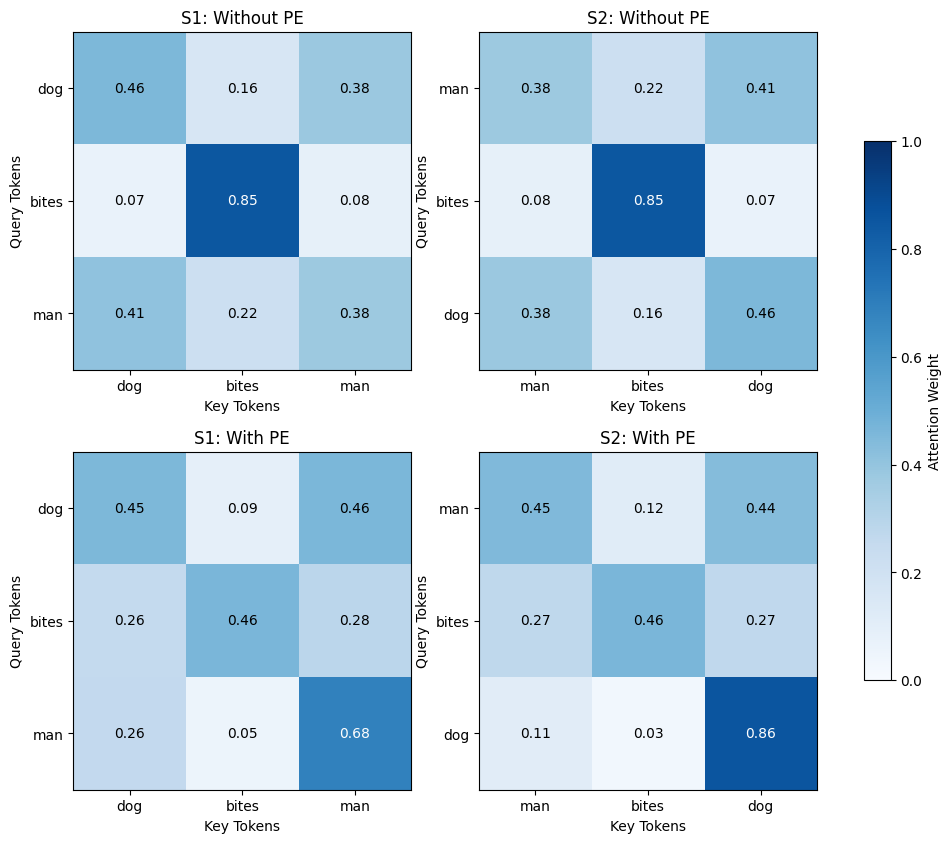

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

attention_matrices = [
    (A1_no, "S1: Without PE", S1),
    (A2_no, "S2: Without PE", S2),
    (A1_pe, "S1: With PE", S1),
    (A2_pe, "S2: With PE", S2)
]

for ax, (attention, title, tokens) in zip(
    axes.flat, attention_matrices
):
    im = ax.imshow(
        attention,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    ax.set_xticks(range(len(tokens)))
    ax.set_yticks(range(len(tokens)))

    ax.set_xticklabels(tokens)
    ax.set_yticklabels(tokens)

    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")
    ax.set_title(title)

    for i in range(len(tokens)):
        for j in range(len(tokens)):
            value = attention[i, j]

            ax.text(
                j, i, f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if value > 0.5 else "black"
            )

fig.colorbar(im, ax=axes, shrink=0.7, label="Attention Weight")
plt.savefig("permutation_experiment.png", dpi=300, bbox_inches="tight")
plt.show()

# 17. Core implementation — Transformer block + 18. Kiểm tra shape

In [55]:
from My_Transformers import TransformerBlock
import torch

torch.manual_seed(42)

B = 8
T = 100
d_model = 128
n_heads = 4
d_ff = 512

X = torch.randn(B, T, d_model)

model = TransformerBlock(
    d_model=d_model,
    n_heads=n_heads,
    d_ff=d_ff
)

output = model(X, verbose=True)

assert output.shape == X.shape

print("\nAll output shape checks passed!")


Input X:                       (8, 100, 128)
Q before split:                (8, 100, 128)
K before split:                (8, 100, 128)
V before split:                (8, 100, 128)
Q after split:                 (8, 4, 100, 32)
K after split:                 (8, 4, 100, 32)
V after split:                 (8, 4, 100, 32)
Attention scores:              (8, 4, 100, 100)
Attention weights:             (8, 4, 100, 100)
Attention output per head:     (8, 4, 100, 32)
Concatenated heads:            (8, 100, 128)
Attention projection:          (8, 100, 128)
After Residual + Norm 1:       (8, 100, 128)
FFN hidden:                    (8, 100, 512)
FFN output:                    (8, 100, 128)
Final output:                  (8, 100, 128)

All output shape checks passed!


# 19. Experiment 2 — Number of attention heads

## Config

In [56]:
SEED = 42
D_MODEL = 128
D_FF = 512
N_HEADS_LIST = [1, 2, 4, 8]

SEQ_LEN = 100
VOCAB_SIZE = 50
N_TRAIN = 2000
N_TEST = 500

EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

## Data

In [57]:
DATA_PATH = "/home/vitquay1708/Study_Space/NLP/lab4/imdb/IMDB Dataset.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.head())
print(df["sentiment"].value_counts())
print(df.isnull().sum())
df = df.dropna(subset=["review", "sentiment"]).copy()

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

assert df["label"].notna().all()
df["label"] = df["label"].astype(int)

(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
review       0
sentiment    0
dtype: int64


In [58]:
import re
import html

def preprocess(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(preprocess)

In [59]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)


print(len(train_df), len(test_df))

40000 10000


In [60]:
from collections import Counter

MAX_VOCAB_SIZE = 20000
MAX_LENGTH = 100
BATCH_SIZE = 32

counter = Counter()

for text in train_df["clean_review"]:
    counter.update(text.split())

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, _ in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
VOCAB_SIZE = max(vocab.values()) + 1
SEQ_LEN = MAX_LENGTH

print("VOCAB_SIZE:", VOCAB_SIZE)
print("SEQ_LEN:", SEQ_LEN)

Vocabulary size: 20000
VOCAB_SIZE: 20000
SEQ_LEN: 100


In [61]:
def encode_text(text, vocab, max_length):
    tokens = text.split()

    ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens[:max_length]
    ]

    # Padding
    ids += [vocab["<PAD>"]] * (max_length - len(ids))

    return ids

In [62]:
import torch
from torch.utils.data import TensorDataset, DataLoader

def create_dataloader(df, max_length, shuffle=False):
    X = [
        encode_text(text, vocab, max_length)
        for text in df["clean_review"]
    ]
    y = df["label"].astype(int).tolist()
    X = torch.tensor(X, dtype=torch.long)
    y = torch.tensor(y, dtype=torch.long)
    dataset = TensorDataset(X, y)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )

train_loader = create_dataloader(train_df, max_length=MAX_LENGTH,shuffle=True)
test_loader = create_dataloader(test_df, max_length=MAX_LENGTH)

In [63]:
input_ids, labels = next(iter(train_loader))

print(input_ids.shape)  # torch.Size([32, 100])
print(labels.shape)     # torch.Size([32])

torch.Size([32, 100])
torch.Size([32])


## Model

In [64]:
import math
import time
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]



class TransformerClassifier(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, vocab_size,max_len):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size,embedding_dim=d_model,padding_idx=0)

        self.positional_encoding = PositionalEncoding(d_model=d_model,max_len=max_len)
        self.transformer = TransformerBlock(d_model=d_model,n_heads=n_heads,d_ff=d_ff)
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, x):
        mask = (x != 0)
        x = self.embedding(x)
        x = self.positional_encoding(x)
        x = self.transformer(x)
        mask_float = mask.unsqueeze(-1).float()
        summed = (x * mask_float).sum(dim=1)
        counts = mask_float.sum(dim=1).clamp(min=1)

        pooled = summed / counts

        return self.classifier(pooled)


Device: cuda


In [65]:
def run_experiment(n_heads):
    # Reset seed for fair comparison
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = TransformerClassifier(
        d_model=D_MODEL,
        n_heads=n_heads,
        d_ff=D_FF,
        vocab_size=VOCAB_SIZE,
        max_len=MAX_LENGTH
    ).to(device)

    num_parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    # -------- Training --------
    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        epoch_loss = 0.0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(inputs)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / len(train_loader)

        print(
            f"Heads={n_heads} | "
            f"Epoch={epoch + 1}/{EPOCHS} | "
            f"Loss={avg_loss:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    # -------- Evaluation --------
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.inference_mode():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)

            logits = model(inputs)
            predictions = logits.argmax(dim=-1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
    torch.save(
    model.state_dict(),
    f"transformer_heads_{n_heads}.pth")

    return {
        "Heads": n_heads,
        "d_k": D_MODEL // n_heads,
        "Parameters": num_parameters,
        "Training time (s)": round(training_time, 2),
        "Accuracy": round(accuracy, 4),
        "F1": round(f1, 4)
    }


In [66]:
def validate_loader(loader, name, vocab_size, num_classes=2):
    print(f"\n=== VALIDATING {name} ===")

    for batch_idx, (inputs, labels) in enumerate(loader):
        # Bring data to CPU for validation
        inputs = inputs.cpu()
        labels = labels.cpu()

        assert inputs.dtype == torch.long, (
            f"Batch {batch_idx}: Invalid input dtype"
        )

        assert labels.dtype == torch.long, (
            f"Batch {batch_idx}: Invalid label dtype"
        )

        assert inputs.min().item() >= 0, (
            f"Batch {batch_idx}: Negative token ID"
        )

        assert inputs.max().item() < vocab_size, (
            f"Batch {batch_idx}: Token ID exceeds vocabulary"
        )

        assert labels.min().item() >= 0, (
            f"Batch {batch_idx}: Negative label"
        )

        assert labels.max().item() < num_classes, (
            f"Batch {batch_idx}: Invalid label"
        )

    print(f"{name}: All batches passed!")


validate_loader(
    train_loader,
    "TRAIN LOADER",
    vocab_size=VOCAB_SIZE
)

validate_loader(
    test_loader,
    "TEST LOADER",
    vocab_size=VOCAB_SIZE
)

inputs, labels = next(iter(train_loader))

print("Input shape:", inputs.shape)
print("Max token ID:", inputs.max().item())
print("Vocabulary size:", VOCAB_SIZE)
print("Sequence length:", MAX_LENGTH)
print("Unique labels:", torch.unique(labels))

assert inputs.max().item() < VOCAB_SIZE
assert inputs.shape[1] <= MAX_LENGTH

print("All checks passed!")


=== VALIDATING TRAIN LOADER ===
TRAIN LOADER: All batches passed!

=== VALIDATING TEST LOADER ===
TEST LOADER: All batches passed!
Input shape: torch.Size([32, 100])
Max token ID: 19985
Vocabulary size: 20000
Sequence length: 100
Unique labels: tensor([0, 1])
All checks passed!


In [67]:
results = []

for n_heads in N_HEADS_LIST:
    print(f"\n{'=' * 45}")
    print(f"EXPERIMENT: n_heads = {n_heads}")
    print(f"{'=' * 45}")

    result = run_experiment(n_heads)
    results.append(result)

df = pd.DataFrame(results)

print("\n========== FINAL RESULTS ==========")
print(df.to_string(index=False))

df.to_csv(
    "attention_heads_experiment.csv",
    index=False
)



EXPERIMENT: n_heads = 1
Heads=1 | Epoch=1/10 | Loss=0.5068
Heads=1 | Epoch=2/10 | Loss=0.3611
Heads=1 | Epoch=3/10 | Loss=0.2938
Heads=1 | Epoch=4/10 | Loss=0.2356
Heads=1 | Epoch=5/10 | Loss=0.1824
Heads=1 | Epoch=6/10 | Loss=0.1365
Heads=1 | Epoch=7/10 | Loss=0.1009
Heads=1 | Epoch=8/10 | Loss=0.0713
Heads=1 | Epoch=9/10 | Loss=0.0535
Heads=1 | Epoch=10/10 | Loss=0.0434

EXPERIMENT: n_heads = 2
Heads=2 | Epoch=1/10 | Loss=0.5022
Heads=2 | Epoch=2/10 | Loss=0.3586
Heads=2 | Epoch=3/10 | Loss=0.2892
Heads=2 | Epoch=4/10 | Loss=0.2296
Heads=2 | Epoch=5/10 | Loss=0.1737
Heads=2 | Epoch=6/10 | Loss=0.1272
Heads=2 | Epoch=7/10 | Loss=0.0894
Heads=2 | Epoch=8/10 | Loss=0.0622
Heads=2 | Epoch=9/10 | Loss=0.0452
Heads=2 | Epoch=10/10 | Loss=0.0360

EXPERIMENT: n_heads = 4
Heads=4 | Epoch=1/10 | Loss=0.4987
Heads=4 | Epoch=2/10 | Loss=0.3584
Heads=4 | Epoch=3/10 | Loss=0.2881
Heads=4 | Epoch=4/10 | Loss=0.2249
Heads=4 | Epoch=5/10 | Loss=0.1659
Heads=4 | Epoch=6/10 | Loss=0.1138
Heads=4 | Epo

# Experiment 3 — Attention head diversity

In [68]:
attention_model = TransformerClassifier(
    d_model=128,
    n_heads=4,
    d_ff=512,
    vocab_size=len(vocab),
    max_len=MAX_LENGTH
).to(device)

attention_model.load_state_dict(
    torch.load(
        "transformer_heads_4.pth",
        map_location=device,
        weights_only=True
    )
)

attention_model.eval()

TransformerClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (positional_encoding): PositionalEncoding()
  (transformer): TransformerBlock(
    (W_q): Linear(in_features=128, out_features=128, bias=True)
    (W_k): Linear(in_features=128, out_features=128, bias=True)
    (W_v): Linear(in_features=128, out_features=128, bias=True)
    (W_o): Linear(in_features=128, out_features=128, bias=True)
    (fc1): Linear(in_features=128, out_features=512, bias=True)
    (fc2): Linear(in_features=512, out_features=128, bias=True)
    (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
    (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (classifier): Linear(in_features=128, out_features=2, bias=True)
)

In [69]:
import torch.nn.functional as F
@torch.no_grad()
def extract_attention_weights(model, input_ids, pad_id=0):
    model.eval()

    device = next(model.parameters()).device
    input_ids = input_ids.to(device)

    # 1. Embedding + Positional Encoding
    x = model.embedding(input_ids)
    x = model.positional_encoding(x)

    # 2. Access trained TransformerBlock
    block = model.transformer

    B, T, D = x.shape

    # 3. Project Q and K
    Q = block.W_q(x)
    K = block.W_k(x)

    # 4. Split into multiple heads
    Q = Q.reshape(
        B, T, block.n_heads, block.d_k
    ).transpose(1, 2)

    K = K.reshape(
        B, T, block.n_heads, block.d_k
    ).transpose(1, 2)

    # 5. Compute attention scores
    scores = Q @ K.transpose(-2, -1)
    scores = scores / (block.d_k ** 0.5)

    # 6. Apply the same padding mask as training
    attention_mask = input_ids != pad_id
    key_mask = attention_mask[:, None, None, :]

    scores = scores.masked_fill(
        ~key_mask,
        torch.finfo(scores.dtype).min
    )

    # 7. Compute attention weights
    weights = F.softmax(scores, dim=-1)

    weights = weights.masked_fill(
        ~key_mask, 0.0
    )

    return weights.cpu()


In [70]:
inputs, labels = next(iter(test_loader))

# Select the first sample
input_ids = inputs[:1]

attention_weights = extract_attention_weights(
    attention_model,
    input_ids,
    pad_id=vocab["<PAD>"]
)

print("Attention shape:", attention_weights.shape)

Attention shape: torch.Size([1, 4, 100, 100])


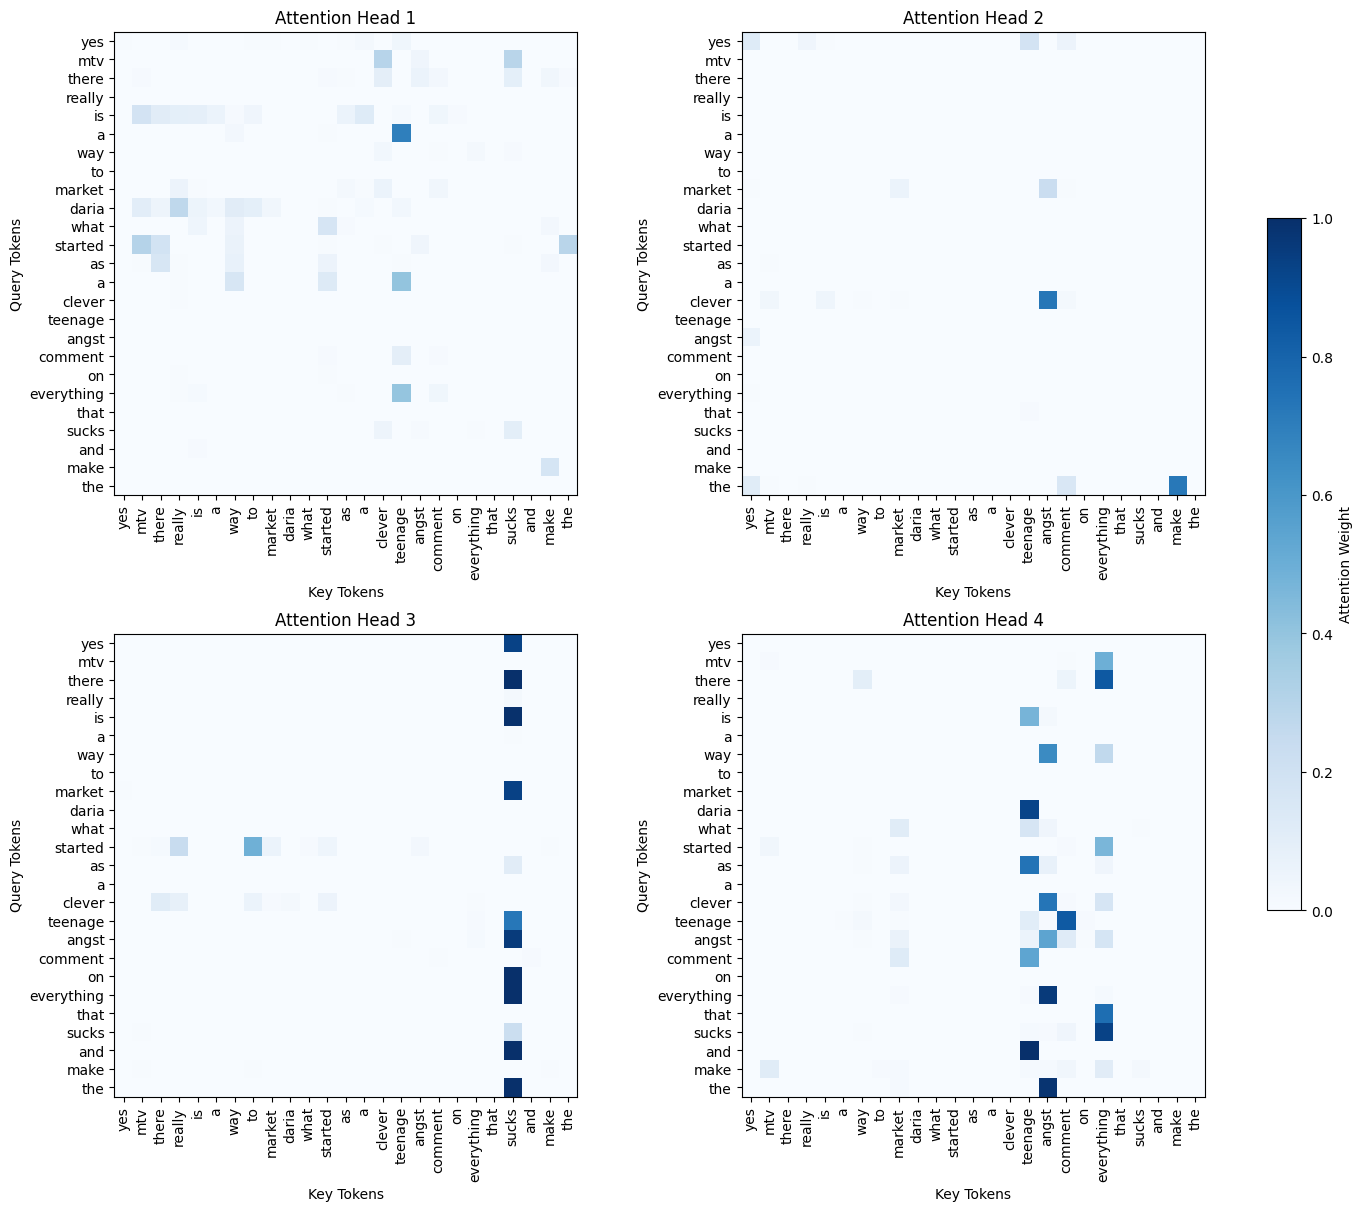

In [71]:

import numpy as np
import matplotlib.pyplot as plt

# Reverse vocabulary
id_to_token = {
    idx: token
    for token, idx in vocab.items()
}

# Remove padding positions
pad_id = vocab["<PAD>"]
valid_ids = input_ids[0][input_ids[0] != pad_id].tolist()

tokens = [
    id_to_token.get(idx, "<UNK>")
    for idx in valid_ids
]

seq_len = len(tokens)

# Shape: (n_heads, seq_len, seq_len)
A = attention_weights[0, :, :seq_len, :seq_len].numpy()

# Limit display to 25 tokens for readability
display_len = min(seq_len, 25)
display_A = A[:, :display_len, :display_len]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12),
    constrained_layout=True
)

# Shared color scale across all heads
vmax = max(float(display_A.max()), 1e-6)

for h, ax in enumerate(axes.flat):
    im = ax.imshow(
        display_A[h],
        cmap="Blues",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(f"Attention Head {h + 1}")

    ax.set_xticks(range(display_len))
    ax.set_yticks(range(display_len))

    ax.set_xticklabels(
        tokens[:display_len],
        rotation=90
    )
    ax.set_yticklabels(tokens[:display_len])

    ax.set_xlabel("Key Tokens")
    ax.set_ylabel("Query Tokens")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    shrink=0.65,
    label="Attention Weight"
)

plt.savefig(
    "attention_head_diversity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Experiment 4 — Transformer vs RNN/LSTM

## LSTM

In [72]:
class LSTMClassifier(nn.Module):
  def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embedding_dim=embed_dim, padding_idx=0)
    self.lstm = nn.LSTM(input_size=embed_dim, hidden_size=hidden_dim, batch_first=True)
    self.classifier = nn.Linear(hidden_dim, num_classes)

  def forward(self, input_ids):
    lengths = (input_ids != 0).sum(dim=1).cpu()
    x = self.embedding(input_ids)
    packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
    _, (h_n, _) = self.lstm(packed)
    context = h_n[-1]
    return self.classifier(context)


lstm_model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embed_dim=D_MODEL,
    hidden_dim=64,
    num_classes=2
).to(device)

In [73]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr = LEARNING_RATE)

start_time = time.perf_counter()

for epoch in range(EPOCHS):
  lstm_model.train()
  total_loss = 0.0

  for input_ids, labels in train_loader:
    input_ids = input_ids.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    # print(lstm_model(input_ids))
    logits = lstm_model(input_ids)
    loss = criterion(logits, labels)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * labels.size(0)

  avg_loss = total_loss / len(train_loader.dataset)
  print(f"Epoch {epoch+1}/{EPOCHS} - Loss: {avg_loss:.4f}")

if device == "cuda":
  torch.cuda.synchronize()

lstm_time = time.perf_counter() - start_time
print(f"LSTM time: {lstm_time:.2f}")

Epoch 1/10 - Loss: 0.6509
Epoch 2/10 - Loss: 0.4330
Epoch 3/10 - Loss: 0.3102
Epoch 4/10 - Loss: 0.2347
Epoch 5/10 - Loss: 0.1658
Epoch 6/10 - Loss: 0.1083
Epoch 7/10 - Loss: 0.0692
Epoch 8/10 - Loss: 0.0447
Epoch 9/10 - Loss: 0.0347
Epoch 10/10 - Loss: 0.0223
LSTM time: 243.47


In [74]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

In [75]:
lstm_model.eval()

y_preds = []
y_labels = []

device = "cuda"
with torch.inference_mode():
  for input_ids, labels in test_loader:
    input_ids = input_ids.to(device, dtype=torch.long)
    logits = lstm_model(input_ids)
    predictions = torch.argmax(logits, dim=1)
    y_preds.extend(predictions.cpu().numpy())
    y_labels.extend(labels.numpy())

lstm_accuracy = accuracy_score(y_labels, y_preds)
lstm_f1 = f1_score(y_labels, y_preds)
lstm_recall = recall_score(y_labels, y_preds)
lstm_precision = precision_score(y_labels, y_preds)
lstm_parameters = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)

## Attention 4 heads

In [76]:
attention_model.eval()

y_preds = []
y_labels = []

device = "cuda"
with torch.inference_mode():
  for input_ids, labels in test_loader:
    input_ids = input_ids.to(device, dtype=torch.long)
    logits = attention_model(input_ids)
    predictions = torch.argmax(logits, dim=1)
    y_preds.extend(predictions.cpu().numpy())
    y_labels.extend(labels.numpy())

attention_accuracy = accuracy_score(y_labels, y_preds)
attention_f1 = f1_score(y_labels, y_preds)
attention_recall = recall_score(y_labels, y_preds)
attention_precision = precision_score(y_labels, y_preds)
attention_parameters = sum(p.numel() for p in attention_model.parameters() if p.requires_grad)

In [77]:
ex4_results = pd.DataFrame({
    "Model": ["LSTM", "Attention 4 heads"],
    "Accuracy": [lstm_accuracy, attention_accuracy],
    "F1": [lstm_f1, attention_f1],
    "Recall": [lstm_recall, attention_recall],
    "Precision": [lstm_precision, attention_precision],
    "Training time (s)": [lstm_time, results[2]["Training time (s)"]],
    "Parameters": [lstm_parameters, attention_parameters]
})
ex4_df = pd.DataFrame(ex4_results)

print("\n========== FINAL RESULTS ==========")
print(ex4_df.to_string(index=False))

ex4_df.to_csv(
    "ex4_results.csv",
    index=False
)


========== FINAL RESULTS ==========
            Model  Accuracy       F1  Recall  Precision  Training time (s)  Parameters
             LSTM    0.8294 0.827398  0.8178   0.837224         243.470934     2609794
Attention 4 heads    0.8159 0.816688  0.8202   0.813206         135.100000     2758530


# Experiment 5 — Sequence length

In [78]:
original_lengths = np.array([
    len(str(text).split())
    for text in test_df["clean_review"].fillna("")
])

def calculate_retention(length):
    retained = np.minimum(original_lengths, length)
    avg_retained = retained.mean()
    retention_rate = (
        retained.sum() / original_lengths.sum() * 100
        if original_lengths.sum() > 0 else 0
    )
    return avg_retained, retention_rate


def calculate_attention_memory(length):
    elements = BATCH_SIZE * 4 * length**2
    bytes_used = elements * 4
    return bytes_used / (1024**2)

In [79]:

max_length = [32, 64, 128, 256]
ex5_results = []
for length in max_length:
  print(f"EXPERIMENT: MAX_LENGTH = {length}")
  ex5_model = TransformerClassifier(D_MODEL, 4, D_FF, VOCAB_SIZE, length).to("cuda")
  torch.manual_seed(42)
  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.AdamW(ex5_model.parameters(), lr = LEARNING_RATE)

  ex5_model.train()

  torch.cuda.synchronize()

  start_time = time.perf_counter()
  ex5_train_loader = create_dataloader(train_df, max_length=length, shuffle=True)
  ex5_test_loader = create_dataloader(test_df, max_length=length)

  for epoch in range(EPOCHS):
    total_loss = 0.0

    for input_ids, labels in ex5_train_loader:
      input_ids = input_ids.to("cuda")
      labels = labels.to("cuda")
      optimizer.zero_grad()
      logits = ex5_model(input_ids)
      loss = criterion(logits, labels)

      loss.backward()
      optimizer.step()
      total_loss += loss.item()

    avg_loss = total_loss/len(ex5_train_loader)
    print(f"Epoch {epoch + 1}/{EPOCHS} | Loss: {avg_loss:.4f}")
  torch.cuda.synchronize()
  training_time = time.perf_counter() - start_time

  ex5_model.eval()
  y_true = []
  y_preds = []

  with torch.inference_mode():
    for input_ids, labels in ex5_test_loader:
      input_ids = input_ids.to("cuda")
      logits = ex5_model(input_ids)
      predictions = torch.argmax(logits, dim=-1).cpu().tolist()
      y_true.extend(labels.cpu().tolist())
      y_preds.extend(predictions)
  
  acc = accuracy_score(y_true=y_true, y_pred=y_preds)
  f1 = f1_score(y_true=y_true, y_pred=y_preds)
  avg_retained, retention_rate = calculate_retention(length)
  attention_mem = calculate_attention_memory(length)

  ex5_results.append({
      "Length": length,
      "Avg tokens retained": round(avg_retained, 2),
      "Retention (%)": round(retention_rate, 2),
      "Attention memory (MiB)": round(attention_mem, 2),
      "Training time (s)": round(training_time, 2),
      "Accuracy": round(acc, 4),
      "F1": round(f1, 4)
  })

EXPERIMENT: MAX_LENGTH = 32
Epoch 1/10 | Loss: 0.5952
Epoch 2/10 | Loss: 0.4969
Epoch 3/10 | Loss: 0.4327
Epoch 4/10 | Loss: 0.3703
Epoch 5/10 | Loss: 0.3116
Epoch 6/10 | Loss: 0.2545
Epoch 7/10 | Loss: 0.2011
Epoch 8/10 | Loss: 0.1506
Epoch 9/10 | Loss: 0.1109
Epoch 10/10 | Loss: 0.0846
EXPERIMENT: MAX_LENGTH = 64
Epoch 1/10 | Loss: 0.5414
Epoch 2/10 | Loss: 0.4198
Epoch 3/10 | Loss: 0.3446
Epoch 4/10 | Loss: 0.2788
Epoch 5/10 | Loss: 0.2184
Epoch 6/10 | Loss: 0.1629
Epoch 7/10 | Loss: 0.1164
Epoch 8/10 | Loss: 0.0818
Epoch 9/10 | Loss: 0.0637
Epoch 10/10 | Loss: 0.0474
EXPERIMENT: MAX_LENGTH = 128
Epoch 1/10 | Loss: 0.4854
Epoch 2/10 | Loss: 0.3391
Epoch 3/10 | Loss: 0.2673
Epoch 4/10 | Loss: 0.2069
Epoch 5/10 | Loss: 0.1475
Epoch 6/10 | Loss: 0.0977
Epoch 7/10 | Loss: 0.0624
Epoch 8/10 | Loss: 0.0411
Epoch 9/10 | Loss: 0.0315
Epoch 10/10 | Loss: 0.0239
EXPERIMENT: MAX_LENGTH = 256
Epoch 1/10 | Loss: 0.4408
Epoch 2/10 | Loss: 0.2832
Epoch 3/10 | Loss: 0.2167
Epoch 4/10 | Loss: 0.1622

In [80]:
ex5_df = pd.DataFrame(ex5_results)

print("\n========== EXPERIMENT 5 RESULTS ==========")
print(ex5_df.to_string(index=False))

ex5_df.to_csv(
    "experiment5_sequence_length.csv",
    index=False
)



========== EXPERIMENT 5 RESULTS ==========
 Length  Avg tokens retained  Retention (%)  Attention memory (MiB)  Training time (s)  Accuracy     F1
     32                31.98          13.90                     0.5             180.06    0.7275 0.7317
     64                63.25          27.48                     2.0             209.44    0.7678 0.7573
    128               118.97          51.69                     8.0             196.38    0.8279 0.8264
    256               177.41          77.09                    32.0             245.89    0.8617 0.8609


# Application — Transformer text classification

In [81]:
test_cases = [
    # =========================================
    # 1. SHORT SENTENCES
    # =========================================
    {
        "category": "short",
        "text": "this movie is amazing",
        "expected": 1
    },
    {
        "category": "short",
        "text": "i hate this movie",
        "expected": 0
    },
    {
        "category": "short",
        "text": "the acting was terrible",
        "expected": 0
    },

    # =========================================
    # 2. LONG SENTENCES
    # =========================================
    {
        "category": "long",
        "text": (
            "i watched this movie last night and i was "
            "surprised by how much i enjoyed it "
            "the story begins slowly but gradually becomes "
            "more interesting as the characters develop "
            "the actors deliver convincing performances "
            "and the dialogue feels natural and believable "
            "the cinematography is beautiful and the music "
            "fits perfectly with the atmosphere of the film "
            "there are some scenes that could have been "
            "shorter but they do not seriously affect "
            "the overall experience "
            "by the time the movie reaches its final act "
            "the emotional impact becomes much stronger "
            "and the ending feels satisfying and meaningful "
            "i would definitely recommend this film "
            "to anyone who enjoys thoughtful stories "
            "with memorable characters and excellent acting"
        ),
        "expected": 1
    },
    {
        "category": "long",
        "text": (
            "i had high expectations for this movie "
            "because the trailer looked very promising "
            "and the cast included several talented actors "
            "unfortunately the final result was disappointing "
            "the story is confusing and many important events "
            "are never properly explained "
            "the characters make strange decisions "
            "that do not fit their personalities "
            "the dialogue often sounds unnatural "
            "and several scenes feel completely unnecessary "
            "even though the visual effects are impressive "
            "they cannot compensate for the weak screenplay "
            "the pacing becomes worse in the second half "
            "and the ending leaves many questions unanswered "
            "after spending so much time watching this film "
            "i felt that the experience was a waste of time "
            "and i would not recommend it to my friends"
        ),
        "expected": 0
    },
    {
        "category": "long",
        "text": (
            "the movie starts with an interesting idea "
            "and introduces several characters who seem "
            "ordinary at first but gradually become "
            "more complex as the story progresses "
            "at the beginning i was not particularly "
            "impressed by the slow pacing and simple dialogue "
            "however the film slowly reveals important details "
            "about the characters and their relationships "
            "the director uses small emotional moments "
            "to build tension and develop the central conflict "
            "some scenes are predictable and a few supporting "
            "characters do not receive enough attention "
            "but the main performances are strong "
            "and the story remains engaging throughout "
            "the second half of the movie contains "
            "several memorable scenes that successfully "
            "connect earlier events with the final resolution "
            "although the film has noticeable weaknesses "
            "its emotional depth and satisfying conclusion "
            "make it a rewarding experience overall"
        ),
        "expected": 1
    },

    # =========================================
    # 3. NEGATION
    # =========================================
    {
        "category": "negation",
        "text": "this movie is not good",
        "expected": 0
    },
    {
        "category": "negation",
        "text": "this movie is not bad at all",
        "expected": 1
    },
    {
        "category": "negation",
        "text": "i cannot say that i enjoyed this movie",
        "expected": 0
    },

    # =========================================
    # 4. CONTRAST
    # =========================================
    {
        "category": "contrast",
        "text": (
            "the beginning was boring but "
            "the ending was absolutely wonderful"
        ),
        "expected": 1
    },
    {
        "category": "contrast",
        "text": (
            "the actors were excellent but "
            "the story was terrible and disappointing"
        ),
        "expected": 0
    },
    {
        "category": "contrast",
        "text": (
            "although the movie was very long "
            "i enjoyed every minute of it"
        ),
        "expected": 1
    },

    # =========================================
    # 5. AMBIGUOUS SENTIMENT
    # =========================================
    {
        "category": "ambiguous",
        "text": (
            "the movie was interesting in some ways "
            "but i am not sure whether i liked it"
        ),
        "expected": None
    },
    {
        "category": "ambiguous",
        "text": (
            "some scenes were enjoyable while "
            "others were disappointing"
        ),
        "expected": None
    },
    {
        "category": "ambiguous",
        "text": (
            "i expected something different "
            "but i cannot decide if that is good or bad"
        ),
        "expected": None
    }
]


In [82]:
attention_model.eval()

texts = [case["text"] for case in test_cases]
encoded = [encode_text(text, vocab, MAX_LENGTH) for text in texts]
input_ids = torch.tensor(encoded, dtype=torch.long).to(device)

with torch.inference_mode():
  logits = attention_model(input_ids)
  prob = torch.softmax(logits, dim=-1)
  predictions = prob.argmax(dim=-1)

predictions = predictions.cpu().tolist()
prob = prob.cpu().tolist()
app_results = []
for i, case in enumerate(test_cases):
  pred = predictions[i]
  expected = case["expected"]
  app_results.append({
      "Category": case["category"],
      "Text": case["text"],
      "Tokens": len(case["text"].split()),
      "Expected": expected,
      "Predicted": pred,
      "P(Positive)": round(float(prob[i][1]), 4),
      "Correct": (
          pred == expected
          if expected is not None else None
      )
  })
app_results = pd.DataFrame(app_results)
print(app_results.to_string(index=False))

app_results.to_csv(
    "qualitative_sentiment_test.csv",
    index=False
)

 Category                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               Text  Tokens  Expected  Predicted  P(Positive) Correct
    short                                                                

# Experiment 6 — Pooling strategy

In [83]:
import torch
import torch.nn as nn


class TransformerClassifierPooling(nn.Module):
    def __init__(self,d_model,n_heads,d_ff,vocab_size,max_len,pooling="mean"):
        super().__init__()
        assert pooling in ["mean", "cls"]
        self.pooling = pooling
        self.pad_id = 0
        self.embedding = nn.Embedding(vocab_size,d_model,padding_idx=self.pad_id)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.positional_encoding = PositionalEncoding(d_model, max_len=max_len + 1)
        self.transformer = TransformerBlock(d_model, n_heads, d_ff)
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, input_ids):
        B, T = input_ids.shape
        token_mask = input_ids != self.pad_id
        # 1. Token embedding
        x = self.embedding(input_ids)
        # 2. Prepend CLS embedding
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)

        #3.Extend attention mask for CLS
        cls_mask = torch.ones(B, 1,dtype=torch.bool,device=input_ids.device)
        attention_mask = torch.cat([cls_mask, token_mask], dim=1)
        x = self.positional_encoding(x)
        x = self.transformer(x,attention_mask=attention_mask)
        if self.pooling == "mean":
            token_outputs = x[:, 1:, :]
            mask = token_mask.unsqueeze(-1).to(x.dtype)
            summed = (token_outputs * mask).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)
            pooled = summed / counts
        elif self.pooling == "cls":
            pooled = x[:, 0, :]
        logits = self.classifier(pooled)

        return logits


In [84]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
MAX_LENGTH = next(iter(train_loader))[0].shape[1]
assert next(iter(test_loader))[0].shape[1] == MAX_LENGTH


def run_pooling_experiment(pooling):
    torch.manual_seed(SEED)
    model = TransformerClassifierPooling(
        d_model=D_MODEL,
        n_heads=4,
        d_ff=D_FF,
        vocab_size=VOCAB_SIZE,
        max_len=MAX_LENGTH,
        pooling=pooling
    ).to(device)
    experiment_train_loader = DataLoader(
        train_loader.dataset,
        batch_size=train_loader.batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    num_parameters = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    model.train()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        total_loss = 0.0

        for input_ids, labels in experiment_train_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(input_ids)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(experiment_train_loader)

        print(
            f"{pooling.upper()} | "
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {avg_loss:.4f}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    model.eval()

    y_true = []
    y_pred = []

    with torch.inference_mode():
        for input_ids, labels in test_loader:
            input_ids = input_ids.to(device)

            logits = model(input_ids)
            predictions = logits.argmax(dim=-1)

            y_true.extend(labels.cpu().tolist())
            y_pred.extend(predictions.cpu().tolist())

    accuracy = accuracy_score(y_true, y_pred)

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Save trained model
    torch.save(
        model.state_dict(),
        f"transformer_pooling_{pooling}.pth"
    )

    return {
        "Pooling": pooling,
        "Parameters": num_parameters,
        "Accuracy": round(accuracy, 4),
        "F1": round(f1, 4),
        "Training time (s)": round(training_time, 2)
    }

ex6_results = []
for pooling in ["mean", "cls"]:
    print(f"\n{'=' * 45}")
    print(f"EXPERIMENT: {pooling.upper()} POOLING")
    print(f"{'=' * 45}")

    result = run_pooling_experiment(pooling)
    ex6_results.append(result)


ex6_df = pd.DataFrame(ex6_results)

print("\n========== EXPERIMENT 6 RESULTS ==========")
print(ex6_df.to_string(index=False))

ex6_df.to_csv(
    "experiment6_pooling.csv",
    index=False
)



EXPERIMENT: MEAN POOLING
MEAN | Epoch 1/10 | Loss: 0.5120
MEAN | Epoch 2/10 | Loss: 0.3688
MEAN | Epoch 3/10 | Loss: 0.2935
MEAN | Epoch 4/10 | Loss: 0.2302
MEAN | Epoch 5/10 | Loss: 0.1718
MEAN | Epoch 6/10 | Loss: 0.1150
MEAN | Epoch 7/10 | Loss: 0.0729
MEAN | Epoch 8/10 | Loss: 0.0483
MEAN | Epoch 9/10 | Loss: 0.0365
MEAN | Epoch 10/10 | Loss: 0.0257

EXPERIMENT: CLS POOLING
CLS | Epoch 1/10 | Loss: 0.5403
CLS | Epoch 2/10 | Loss: 0.4189
CLS | Epoch 3/10 | Loss: 0.3437
CLS | Epoch 4/10 | Loss: 0.2856
CLS | Epoch 5/10 | Loss: 0.2413
CLS | Epoch 6/10 | Loss: 0.1974
CLS | Epoch 7/10 | Loss: 0.1647
CLS | Epoch 8/10 | Loss: 0.1317
CLS | Epoch 9/10 | Loss: 0.1083
CLS | Epoch 10/10 | Loss: 0.0867

========== EXPERIMENT 6 RESULTS ==========
Pooling  Parameters  Accuracy     F1  Training time (s)
   mean     2758658    0.8161 0.8161             217.71
    cls     2758658    0.8087 0.8087             233.70
